In [1]:
#import libraries
from arcgis.gis import GIS
from arcgis.apps.dashboards import DashboardManager, DependencyOptions,ItemMapping, LayerMapping, FieldMapping

In [2]:
#connect to ArcGIS Online 
gis = GIS(profile='my_online_admin_profile')

In [3]:
#Instantiate DashboardManager for a specific dashboard item
dashboard_manager = DashboardManager('8b0248a382f645d69fb9b172a358233a', gis)
dashboard_manager

### Get dashboard dependencies

In [4]:
#Get dependencies with layers and fields
options = DependencyOptions(include_layers=True, include_fields=True)
dependencies= dashboard_manager.get_dependencies(options)
dependencies

[ItemResult(item_id='32071df690f2434ebe5d40641d53bd21', source=None, layers=[LayerResult(id='1994aa7ab78-layer-5', sublayer_id=None, fields=[FieldResult(name='OBJECTID'), FieldResult(name='CRSDepTime'), FieldResult(name='DepartureTime'), FieldResult(name='Diverted'), FieldResult(name='Cancelled'), FieldResult(name='dayOfWeek'), FieldResult(name='delayed'), FieldResult(name='CarrierDelay'), FieldResult(name='LateAircraftDelay'), FieldResult(name='NASDelay'), FieldResult(name='WeatherDelay'), FieldResult(name='SecurityDelay'), FieldResult(name='OriginCityName'), FieldResult(name='DestCityName')]), LayerResult(id='1994aa7ab76-layer-4', sublayer_id=None, fields=[FieldResult(name='OBJECTID'), FieldResult(name='CRSArrTime'), FieldResult(name='ArrivalTime'), FieldResult(name='Cancelled'), FieldResult(name='Diverted'), FieldResult(name='LateAircraftDelay'), FieldResult(name='CarrierDelay'), FieldResult(name='NASDelay'), FieldResult(name='WeatherDelay'), FieldResult(name='SecurityDelay'), Field

### Update dashboard dependencies

In [5]:
#define item mapping
item_mapping = ItemMapping(
            source_item_id="0755d6ca21bf4dcebc3baa1c742336a4",
            target_item_id="32071df690f2434ebe5d40641d53bd21",
            layer_mappings=[
                LayerMapping(
                    source_layer_id='1994e52a6b7-layer-130', # web map operational layer ID
                    target_layer_id='1994aa9cbbd-layer-131', 
                    source_sublayer_id=None,
                    target_sublayer_id=None,
                    field_mappings=[
                        FieldMapping(source_name="ObjectId", target_name="FID"),
                        FieldMapping(source_name="DepTime", target_name="DepartureTime"),
                        FieldMapping(source_name="ArrTime", target_name="ArrivalTime"),
                    ]
                )
            ]
        )

### Copy the dashboard within the same Organization

<Item title:"Airlines Performance at ATL" type:Dashboard owner:MMajumdar_geosaurus>
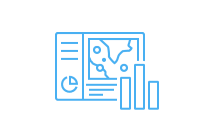

In [6]:
#Copy dashboard with new mappings
copied_item = dashboard_manager.copy(title="Airlines Performance at ATL", folder="Dashboards", item_mapping=[item_mapping])
copied_item

### Upgrade dashboard 

In [7]:
#Upgrade dashboard
upgraded_dashboard = dashboard_manager.upgrade()

#print upgraded dashboard item data to verify the version
print(upgraded_dashboard.get_data()['version'])

4.34.0
